In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings('ignore')

In [34]:
df=pd.read_csv(r"C:\Users\CSEC2\Downloads\Mall_Customers.csv")
print(df.head)
print(df.info())
print(df.isnull().sum())

<bound method NDFrame.head of      CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]>
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 1

In [35]:
from sklearn.preprocessing import StandardScaler
X=df[['Annual Income (k$)','Spending Score (1-100)']]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

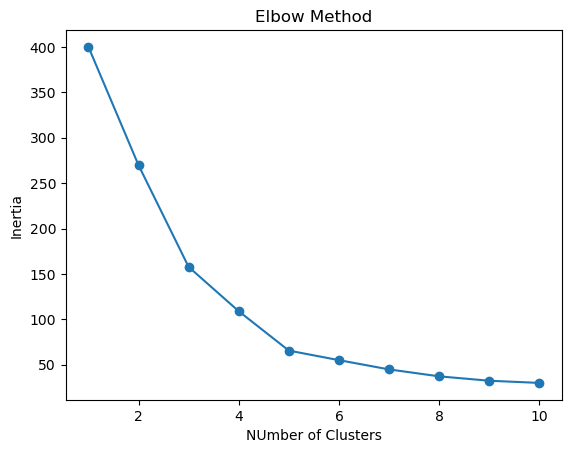

In [36]:
from sklearn.cluster import KMeans
inertias=[]
for k in range(1,11):
    model=KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)
plt.plot(range(1,11),inertias,marker='o')
plt.xlabel("NUmber of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

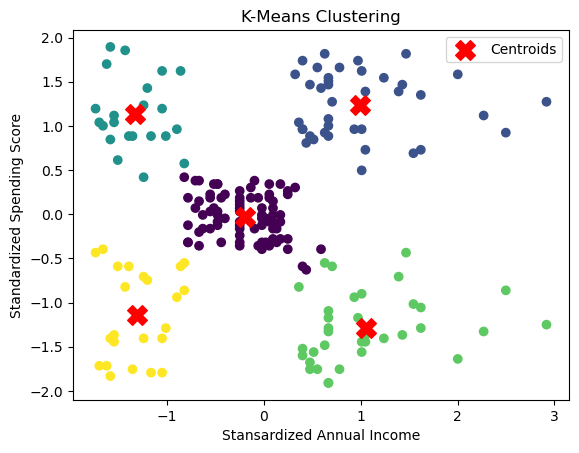

In [43]:
k=5
Kmeans=KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
Kmeans_labels=Kmeans.fit_predict(X_scaled)

plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=Kmeans_labels,
    cmap='viridis'
)
plt.scatter(
    Kmeans.cluster_centers_[:,0],
    Kmeans.cluster_centers_[:,1],
    c='red',
    marker='X',
    s=200,
    label='Centroids'
)
plt.xlabel("Stansardized Annual Income")
plt.ylabel("Standardized Spending Score")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

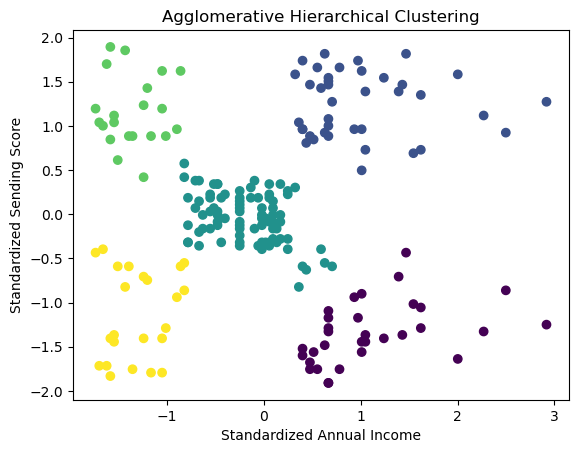

In [44]:
from sklearn.cluster import AgglomerativeClustering
hierarchical=AgglomerativeClustering(
    n_clusters=k,
    linkage='ward'
)
hierarchical_labels=(
    hierarchical.fit_predict(X_scaled)
)
plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c=hierarchical_labels,
    cmap='viridis'
)
plt.xlabel("Standardized Annual Income")
plt.ylabel("Standardized Sending Score")
plt.title("Agglomerative Hierarchical Clustering")
plt.show()

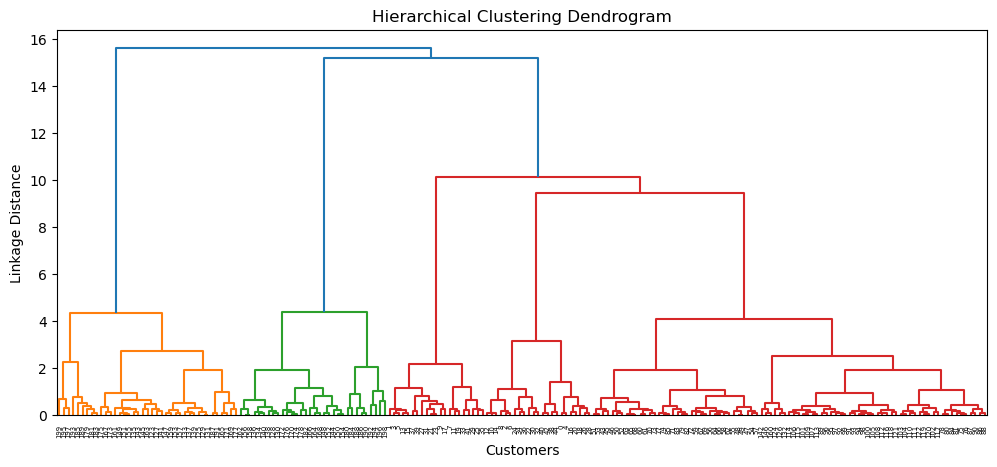

In [47]:
from scipy.cluster.hierarchy import(
    linkage,dendrogram
)
linked=linkage(X_scaled,method='ward')
plt.figure(figsize=(12,5))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Linkage Distance")
plt.show()

In [55]:
from sklearn.metrics import silhouette_score
Kmeans_sil=silhouette_score(
    X_scaled,Kmeans_labels
)
hierarchical_sil=silhouette_score(
    X_scaled,hierarchical_labels
)
def calculate_inertia(X,labels):
    total=0
    for cluster in np.unique(labels):
        points=X[labels == cluster]
        centroid=points.mean(axis=0)
        total+=np.sum(
            (points-centroid)**2
        )
    return total
results=pd.DataFrame({
    "Algorithm":[
        "K-Means","Agglomeative"
    ],
    "Inertia":[
        Kmeans.inertia_,
        calculate_inertia(
            X_scaled,hierarchical_labels
        )
    ],
    "Silhouette Score":[
        Kmeans_sil,hierarchical_sil
    ]
})
print(results)

      Algorithm    Inertia  Silhouette Score
0       K-Means  65.568408          0.554657
1  Agglomeative  66.516504          0.553809
